# Stage 01: Data Understanding
## Hotel Booking Cancellation Prediction

### Project Overview
The objective of this project is to build an end-to-end machine learning system to predict hotel booking cancellations (`is_canceled`). Early detection of likely cancellations allows revenue management and front-desk teams to implement proactive retention strategies, optimize room inventory, and minimize revenue loss from unsold rooms.

### Notebook Objectives
In this first stage of the CRISP-DM methodology (**Data Understanding**), we will:
1. Load the raw dataset and inspect its dimensions, rows, and columns.
2. Classify attributes into numerical and categorical data types.
3. Quantify missing values and understand why they occur.
4. Assess duplicate records and evaluate the trade-offs of duplicate removal.
5. Examine the target variable distribution and class balance.
6. Identify post-outcome variables causing **target leakage** (`reservation_status` and `reservation_status_date`).

### 1. Import Libraries and Configure Environment

* **What we are doing:** Importing standard Python libraries for data manipulation (`pandas`, `numpy`), visualization (`matplotlib`), and file system path handling (`pathlib`).
* **Why we are doing it:** To establish a reproducible analysis environment, format decimal outputs for readability, and ensure output directories exist for saving figures.
* **What the output means:** Confirmation that all dependencies are available and paths are set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Configure display formats
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Set high-resolution plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150

# Output directory for figures
fig_dir = Path("results/figures") if Path("results/figures").exists() else Path("../results/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

print("Environment configured and figure directory ready at:", fig_dir.resolve())

Environment configured and figure directory ready at: C:\Users\abdel\Desktop\Abood Study\My Projects\Python\ML\Data Science Project\hotel-booking-cancellation-prediction\results\figures


### 2. Load the Raw Dataset

* **What we are doing:** Loading the dataset `hotel_bookings.csv` into a pandas DataFrame.
* **Why we are doing it:** The CSV file contains historical bookings from two properties (a Resort Hotel and a City Hotel) between July 2015 and August 2017.
* **What the output means:** Displays total rows and columns loaded, verifying data ingestion integrity.

In [2]:
data_path = Path("data/raw/hotel_bookings.csv") if Path("data/raw/hotel_bookings.csv").exists() else Path("../data/raw/hotel_bookings.csv")
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded from: {data_path}")
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset successfully loaded from: ..\data\raw\hotel_bookings.csv
Dataset Shape: 119,390 rows x 32 columns


### 3. First Look at the Data

* **What we are doing:** Inspecting the first 5 records (`head`) and last 5 records (`tail`) of the dataset.
* **Why we are doing it:** Sanity check to confirm header alignment, column formatting, and preview the raw values stored in each column.
* **What the output means:** Provides a concrete visual representation of the booking records, including lead times, guest demographics, room codes, and booking channels.

In [3]:
# Display first 5 rows
print("--- FIRST 5 ROWS ---")
df.head()

--- FIRST 5 ROWS ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


In [4]:
# Display last 5 rows
print("--- LAST 5 ROWS ---")
df.tail()

--- LAST 5 ROWS ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.00,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.00,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.00,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.00,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.00,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.00,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.00,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.00,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


### 4. Data Types and Attribute Classification

* **What we are doing:** Inspecting data types (`df.info()`) and categorizing the 32 columns into numerical and categorical variables.
* **Why we are doing it:** Machine learning algorithms require distinct handling for numerical features (scaling, outlier handling) versus categorical features (encoding).
* **What the output means:** Confirms the data types stored in memory and lists categorical vs numerical attributes for pipeline planning.

In [5]:
# Concise summary of dataframe structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [6]:
# Categorize columns into Numerical and Categorical
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Total Columns: {len(df.columns)}")
print(f"Numerical Columns ({len(numerical_cols)}):")
print(numerical_cols)
print()
print(f"Categorical Columns ({len(categorical_cols)}):")
print(categorical_cols)

Total Columns: 32
Numerical Columns (20):
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical Columns (12):
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


C:\Users\abdel\AppData\Local\Temp\ipykernel_22972\1378099514.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()


In [7]:
# Unique values count per column
nunique_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Sample Value': df.iloc[0]
})
nunique_summary

,Data Type,Unique Values,Sample Value
hotel,str,2,Resort Hotel
is_canceled,int64,2,0
lead_time,int64,479,342
arrival_date_year,int64,3,2015
arrival_date_month,str,12,July
arrival_date_week_number,int64,53,27
arrival_date_day_of_month,int64,31,1
stays_in_weekend_nights,int64,17,0
stays_in_week_nights,int64,35,0
adults,int64,14,2


### 5. Descriptive Statistics

* **What we are doing:** Generating statistical summaries for numerical columns (`mean`, `std`, `min`, `quartiles`, `max`) and categorical columns (`count`, `unique`, `top`, `freq`).
* **Why we are doing it:** To detect anomalies, extreme values, scale differences, and understand the central tendencies of key features.
* **What the output means:**
  * `lead_time`: Ranges from 0 to 737 days (average ~104 days).
  * `adr` (Average Daily Rate): Ranges from -$6.38 to $5,400.00 (identifying evident data entry anomalies).
  * `adults`, `children`, `babies`: Notice maximums such as 55 adults or 10 children, which will require sanity checks.
  * `hotel`: 2 types, City Hotel is the most frequent (~66.4%).

In [8]:
# Numerical features summary
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.00,0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,119390.00,104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,119390.00,2016.16,0.71,2015.00,2016.00,2016.00,2017.00,2017.00
arrival_date_week_number,119390.00,27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,119390.00,15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,119390.00,0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,119390.00,2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,119390.00,1.86,0.58,0.00,2.00,2.00,2.00,55.00
children,119386.00,0.10,0.40,0.00,0.00,0.00,0.00,10.00
babies,119390.00,0.01,0.10,0.00,0.00,0.00,0.00,10.00


In [9]:
# Categorical features summary
df[categorical_cols].describe().T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### 6. Target Variable Analysis: `is_canceled`

* **What we are doing:** Computing the frequency and proportion of the target variable `is_canceled` (0 = Not Canceled, 1 = Canceled) and visualizing its balance.
* **Why we are doing it:** Checking for class imbalance informs whether we need specialized resampling techniques (SMOTE, class weighting) or specific evaluation metrics (ROC-AUC, Precision, Recall, F1-Score, PR-AUC).
* **What the output means:**
  * 75,166 bookings (62.96%) were not canceled (stayed or completed).
  * 44,224 bookings (37.04%) were canceled.
  * This is a moderately balanced binary classification task (~63% vs ~37%), meaning standard classification models can learn both classes effectively without extreme imbalance corrections.

=== TARGET VARIABLE DISTRIBUTION ===
                  Count  Percentage (%)
Not Canceled (0)  75166           62.96
Canceled (1)      44224           37.04


Figure saved to: ..\results\figures\target_distribution_01.png


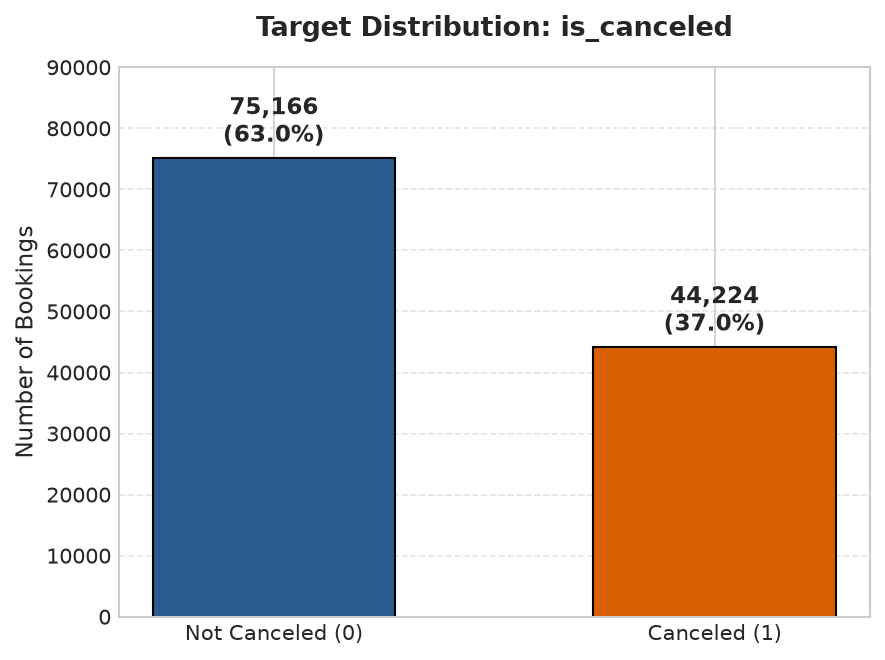

In [10]:
target_counts = df['is_canceled'].value_counts()
target_pct = (df['is_canceled'].value_counts(normalize=True) * 100)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage (%)': target_pct.round(2)
})
target_summary.index = ['Not Canceled (0)', 'Canceled (1)']
print("=== TARGET VARIABLE DISTRIBUTION ===")
print(target_summary)

# Plot target distribution
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(target_summary.index, target_summary['Count'], color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.55)

# Add value and percentage annotations on top of bars
for bar in bars:
    height = bar.get_height()
    pct = height / len(df) * 100
    ax.annotate(f"{height:,}\n({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Target Distribution: is_canceled', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_ylim(0, 90000)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig_path = fig_dir / 'target_distribution_01.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Figure saved to: {fig_path}")
plt.show()

### 7. Initial Data Quality Checks: Missing Values and Duplicates

#### A. Missing Values
* **What we are doing:** Calculating exact missing value counts and percentages across all 32 columns.
* **Why we are doing it:** Missing data must be understood before deciding on imputation strategies or dropping columns in preprocessing.
* **What the output means:**
  1. `company`: 112,593 missing (94.31%). Most guests book as individuals rather than corporate accounts.
  2. `agent`: 16,340 missing (13.69%). Direct bookings made without a travel agency.
  3. `country`: 488 missing (0.41%). Nationality of guest was not recorded.
  4. `children`: 4 missing (0.003%). Four bookings missing children count (safe to impute 0).
  * All remaining 28 columns have **0** missing values.

In [11]:
# Identify columns with missing values
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(3)

missing_df = pd.DataFrame({
    'Missing Count': missing_counts[missing_counts > 0],
    'Missing Percentage (%)': missing_pct[missing_pct > 0]
}).sort_values(by='Missing Count', ascending=False)

print("=== COLUMNS WITH MISSING VALUES ===")
missing_df

=== COLUMNS WITH MISSING VALUES ===


,Missing Count,Missing Percentage (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


#### B. Duplicate Records Analysis & Discussion
* **What we are doing:** Checking the number of completely duplicated rows in the dataset.
* **Why we are doing it:** To assess whether identical rows represent genuine repeated bookings (e.g. tour groups, families booking identical rooms, conference attendees) or accidental data entry duplicates.
* **What the output means:**
  * Exactly 31,994 identical rows (26.80% of the dataset) exist.
  * **Discussion on Duplicate Handling:**
    * In hotel Property Management Systems (PMS), multiple rooms booked under identical parameters (same hotel, arrival date, length of stay, lead time, market segment, and agent) for family members, group tours, or conferences appear as identical rows because guest names and reservation IDs were anonymized/removed for privacy.
    * In the seminal paper introducing this dataset (*Antonio, de Almeida, and Nunes, 2019, Data in Brief*), duplicates were retained to preserve the natural distribution of group bookings.
    * However, keeping duplicates can cause data leakage between train and test splits if identical records fall into both partitions.
    * We explicitly document this trade-off: in the preprocessing stage, we can evaluate model performance both with and without duplicates or ensure deduplicated evaluation.

In [12]:
# Duplicate rows count
duplicate_count = df.duplicated().sum()
duplicate_pct = (duplicate_count / len(df)) * 100

print(f"Total Duplicate Rows: {duplicate_count:,}")
print(f"Duplicate Percentage: {duplicate_pct:.2f}%")
print(f"Remaining Unique Rows if Deduplicated: {len(df) - duplicate_count:,} ({100 - duplicate_pct:.2f}%)")

Total Duplicate Rows: 31,994
Duplicate Percentage: 26.80%
Remaining Unique Rows if Deduplicated: 87,396 (73.20%)


### 8. Crucial Target Leakage Warning: `reservation_status` & `reservation_status_date`

* **What we are doing:** Examining the relationship between `reservation_status`, `reservation_status_date`, and `is_canceled` using a contingency table (crosstab).
* **Why we are doing it:** **Target leakage** occurs when a predictor feature incorporates information that is only known *after* the event to be predicted has already happened. Training a model with leaky features produces artificially inflated (e.g., 100%) test performance that collapses completely in real-world deployment.
* **What the output means:**
  * When `reservation_status` is `'Check-Out'`, `is_canceled` is 0 (100% of the time).
  * When `reservation_status` is `'Canceled'` or `'No-Show'`, `is_canceled` is 1 (100% of the time).
  * `reservation_status_date` records the exact date when the reservation status changed (e.g., date of cancellation or date of check-out), which is also determined post-outcome.
  * **Critical Rule:** Both `reservation_status` and `reservation_status_date` **must be completely removed** before model training.

In [13]:
# Crosstab showing absolute 100% deterministic mapping with target
leakage_crosstab = pd.crosstab(df['reservation_status'], df['is_canceled'], margins=True)
print("=== CONTINGENCY TABLE: reservation_status vs is_canceled ===")
leakage_crosstab

=== CONTINGENCY TABLE: reservation_status vs is_canceled ===


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


In [14]:
# Verification of reservation_status_date as post-outcome timestamp
sample_leakage = df[['hotel', 'reservation_status', 'reservation_status_date', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'is_canceled']].head(5)
print("=== SAMPLE OF POST-OUTCOME LEAKAGE FEATURES ===")
sample_leakage

=== SAMPLE OF POST-OUTCOME LEAKAGE FEATURES ===


,hotel,reservation_status,reservation_status_date,arrival_date_year,arrival_date_month,arrival_date_day_of_month,is_canceled
0,Resort Hotel,Check-Out,2015-07-01,2015,July,1,0
1,Resort Hotel,Check-Out,2015-07-01,2015,July,1,0
2,Resort Hotel,Check-Out,2015-07-02,2015,July,1,0
3,Resort Hotel,Check-Out,2015-07-02,2015,July,1,0
4,Resort Hotel,Check-Out,2015-07-03,2015,July,1,0


### 9. Key Observations & Summary

| Aspect | Finding | Impact on Downstream Steps |
| :--- | :--- | :--- |
| **Dataset Size** | 119,390 rows, 32 columns | Sufficient statistical power for machine learning. |
| **Target Balance** | 62.96% Non-Canceled, 37.04% Canceled | Moderate balance; ROC-AUC and F1 are primary metrics. |
| **Missing Values** | `company` (94.3%), `agent` (13.7%), `country` (0.41%), `children` (4) | Impute `children` with 0, `country` with 'Unknown'/mode, `agent`/`company` with 0 (no agent/company). |
| **Duplicates** | 31,994 rows (26.8%) | Represents PMS group bookings; consider deduplication impact during preprocessing. |
| **Target Leakage** | `reservation_status` & `reservation_status_date` | **Must drop** both features prior to training to avoid 100% artificial accuracy. |
| **Next Stage** | Exploratory Data Analysis | Move to `notebooks/02_exploratory_data_analysis.ipynb` to analyze cancellation drivers. |